# 07 · Libraries: Use, Speed Up, Package, Publish, Contribute

Python's real power is its ecosystem of libraries. This module looks at libraries from every side: using
them well, making slow code fast with compiled extensions, turning your own code into an installable
package, publishing it, managing versions without breaking your users, and contributing to projects you
depend on.

**You will learn**
1. Finding and inspecting libraries: versions, dependencies, documentation
2. Why pure Python loops are slow, and four ways to speed them up: NumPy, Numba, Cython and C (measured)
3. Packaging: a `pyproject.toml`, building a wheel, installing it in a clean environment
4. Publishing to PyPI safely
5. Versions: semantic versioning, specifiers, deprecations and backward compatibility
6. Becoming a contributor

## 1. Inspecting installed libraries

In [1]:
from importlib.metadata import version, requires, metadata
import numpy

print("numpy", version("numpy"), "from", numpy.__file__)
print("pandas requires:", [r for r in (requires("pandas") or []) if "extra" not in r])
print("summary:", metadata("polars")["Summary"])
print(numpy.clip.__doc__.strip().splitlines()[0])      # help(numpy.clip) prints the full documentation

numpy 2.5.4 from /home/patito/Developments/academy/python/.venv/lib/python3.12/site-packages/numpy/__init__.py
pandas requires: ['numpy>=1.22.4; python_version < "3.11"', 'numpy>=1.23.2; python_version == "3.11"', 'numpy>=1.26.0; python_version >= "3.12"', 'python-dateutil>=2.8.2', 'pytz>=2020.1', 'tzdata>=2022.7']
summary: Blazingly fast DataFrame library
Clip (limit) the values in an array.


## 2. Speeding up a hot loop
Python executes each operation through the interpreter, checking types every time. For numeric loops
that is tens to hundreds of times slower than compiled code. The same function, a numerically heavy loop,
implemented five ways:

In [2]:
import math, time, numpy as np

def py_version(n: int) -> float:
    total = 0.0
    for i in range(1, n):
        total += math.sin(i) * math.sqrt(i) / i
    return total

def numpy_version(n: int) -> float:
    i = np.arange(1, n, dtype=np.float64)
    return float(np.sum(np.sin(i) * np.sqrt(i) / i))

N = 5_000_000
def bench(fn, repeat=3):
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter(); value = fn(N); best = min(best, time.perf_counter() - t0)
    return best, value

timings = {}
timings["pure Python"] = bench(py_version, repeat=1)
timings["NumPy (vectorised)"] = bench(numpy_version)
for k, (t, v) in timings.items():
    print(f"{k:<22}{t:8.3f} s   result {v:.6f}")

pure Python              1.596 s   result 1.044289
NumPy (vectorised)       0.194 s   result 1.044289


**Numba** compiles a Python function to machine code the first time it is called (just-in-time). You
keep writing loops; you add one decorator.

In [3]:
from numba import njit

@njit(cache=False)
def numba_version(n):
    total = 0.0
    for i in range(1, n):
        total += math.sin(i) * math.sqrt(i) / i
    return total

numba_version(10)                                   # first call compiles; not timed
timings["Numba (JIT)"] = bench(numba_version)
print(f"Numba {timings['Numba (JIT)'][0]:.3f} s, result {timings['Numba (JIT)'][1]:.6f}")

Numba 0.152 s, result 1.044289


**Cython** is a superset of Python that compiles to C. Declaring C types (`cdef double`) is what makes it
fast. `pyximport` compiles a `.pyx` file on import; real packages compile it at build time instead.

In [4]:
import os, sys, tempfile, importlib, textwrap
work = tempfile.mkdtemp()
with open(os.path.join(work, "fastloop.pyx"), "w") as f:
    f.write(textwrap.dedent("""
        from libc.math cimport sin, sqrt
        def cython_version(long n):
            cdef double total = 0.0
            cdef long i
            for i in range(1, n):
                total += sin(i) * sqrt(i) / i
            return total
    """))
import pyximport
pyximport.install(build_dir=os.path.join(work, "build"), language_level=3, inplace=False)
sys.path.insert(0, work)
fastloop = importlib.import_module("fastloop")
timings["Cython (typed)"] = bench(fastloop.cython_version)
print(f"Cython {timings['Cython (typed)'][0]:.3f} s, result {timings['Cython (typed)'][1]:.6f}")

Cython 0.159 s, result 1.044289


**C through `ctypes`**: write the function in C, compile it into a shared library, call it from Python.
This is how many libraries wrap existing C code (others use `cffi` or, for C++, `pybind11`).

In [5]:
import ctypes, shutil, subprocess
c_src = os.path.join(work, "loop.c")
lib_path = os.path.join(work, "libloop.so")
with open(c_src, "w") as f:
    f.write("""
#include <math.h>
double c_version(long n) {
    double total = 0.0;
    for (long i = 1; i < n; i++) total += sin((double)i) * sqrt((double)i) / i;
    return total;
}
""")
if shutil.which("gcc"):
    subprocess.run(["gcc", "-O2", "-shared", "-fPIC", c_src, "-o", lib_path, "-lm"], check=True)
    lib = ctypes.CDLL(lib_path)
    lib.c_version.argtypes, lib.c_version.restype = [ctypes.c_long], ctypes.c_double
    timings["C via ctypes"] = bench(lib.c_version)
    print(f"C {timings['C via ctypes'][0]:.3f} s, result {timings['C via ctypes'][1]:.6f}")
else:
    print("no C compiler found: install gcc (Linux), Xcode command line tools (macOS) or Build Tools (Windows)")

C 0.149 s, result 1.044289


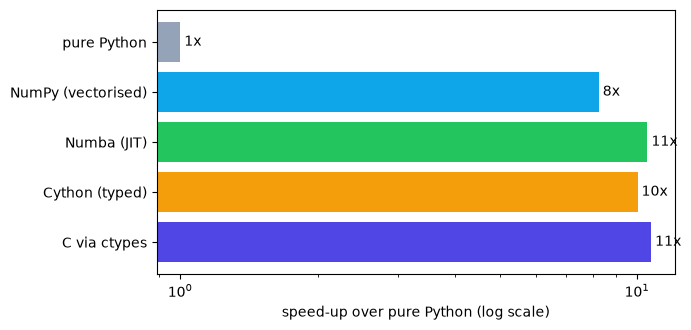

In [6]:
import matplotlib.pyplot as plt
base = timings["pure Python"][0]
names = list(timings)
speedups = [base / timings[k][0] for k in names]
plt.figure(figsize=(7, 3.4))
plt.barh(names, speedups, color=["#94a3b8", "#0ea5e9", "#22c55e", "#f59e0b", "#4f46e5"][:len(names)])
plt.gca().invert_yaxis(); plt.xscale("log"); plt.xlabel("speed-up over pure Python (log scale)")
for y, s in enumerate(speedups):
    plt.text(s, y, f" {s:,.0f}x", va="center")
plt.tight_layout(); plt.show()

All five agree on the result to many decimals, and every alternative is roughly ten times faster than the
pure Python loop. They end up close to each other because the remaining time is spent inside `sin` and
`sqrt` themselves; for loops with cheaper bodies (counting, comparisons, simple arithmetic) the gap to
pure Python is often 50 to 100 times. Which to choose:

| Option | Effort | Best when |
|---|---|---|
| NumPy vectorisation | rewrite as array operations | the computation maps onto whole arrays |
| Numba | one decorator | numeric loops over NumPy arrays and scalars |
| Cython | a typed `.pyx` file plus a build step | you also need to call C libraries, or ship a compiled package |
| C / C++ (ctypes, cffi, pybind11) | write and build native code | wrapping an existing native library |
| Rust (PyO3, maturin) | Rust | new performance-critical libraries (Polars, Pydantic and ruff are built this way) |

Always **profile first** (`cProfile`, `line_profiler`, `py-spy`): speed up the function that actually
takes the time.

## 3. Packaging your own library
A package is a folder with an `__init__.py`; a *distribution* (a **wheel**) is what `pip` installs. All
metadata lives in `pyproject.toml`. Below, a tiny library `ministats` is created, built into a wheel,
checked, and installed in a clean environment.

In [7]:
import pathlib
pkg = pathlib.Path(tempfile.mkdtemp()) / "ministats"
(pkg / "src" / "ministats").mkdir(parents=True)
(pkg / "tests").mkdir()
(pkg / "src" / "ministats" / "__init__.py").write_text(textwrap.dedent("""
    "Tiny statistics helpers (course example)."
    from importlib.metadata import version as _v
    __version__ = _v("ministats")

    def mean(values):
        values = list(values)
        if not values:
            raise ValueError("mean of an empty sequence")
        return sum(values) / len(values)

    def zscores(values):
        values = list(values)
        m = mean(values)
        sd = (sum((v - m) ** 2 for v in values) / len(values)) ** 0.5
        return [(v - m) / sd for v in values]
"""))
(pkg / "tests" / "test_basic.py").write_text("from ministats import mean\n\ndef test_mean():\n    assert mean([1, 2, 3]) == 2\n")
(pkg / "README.md").write_text("# ministats\n\nTiny statistics helpers.\n")
(pkg / "LICENSE").write_text("MIT License\n")
(pkg / "pyproject.toml").write_text(textwrap.dedent("""
    [build-system]
    requires = ["setuptools>=70"]
    build-backend = "setuptools.build_meta"

    [project]
    name = "ministats"
    version = "0.1.0"
    description = "Tiny statistics helpers (course example)"
    readme = "README.md"
    license = "MIT"
    requires-python = ">=3.10"
    dependencies = []                      # e.g. ["numpy>=1.26"]
    authors = [{ name = "Your Name" }]
    classifiers = ["Programming Language :: Python :: 3"]

    [project.optional-dependencies]
    dev = ["pytest>=8"]

    [project.urls]
    Homepage = "https://example.org/ministats"
"""))
print(subprocess.run(["find", str(pkg), "-type", "f"], capture_output=True, text=True).stdout)

/tmp/tmpmx_vde3p/ministats/src/ministats/__init__.py
/tmp/tmpmx_vde3p/ministats/README.md
/tmp/tmpmx_vde3p/ministats/LICENSE
/tmp/tmpmx_vde3p/ministats/tests/test_basic.py
/tmp/tmpmx_vde3p/ministats/pyproject.toml



In [8]:
# build an sdist (source archive) and a wheel; --no-isolation reuses this environment's setuptools (works offline)
r = subprocess.run([sys.executable, "-m", "build", "--no-isolation", str(pkg)], capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])
dist = sorted((pkg / "dist").iterdir())
print([p.name for p in dist])
print(subprocess.run([sys.executable, "-m", "twine", "check", *map(str, dist)], capture_output=True, text=True).stdout)

Successfully built ministats-0.1.0.tar.gz and ministats-0.1.0-py3-none-any.whl
['ministats-0.1.0-py3-none-any.whl', 'ministats-0.1.0.tar.gz']


Checking /tmp/tmpmx_vde3p/ministats/dist/ministats-0.1.0-py3-none-any.whl: PASSED
Checking /tmp/tmpmx_vde3p/ministats/dist/ministats-0.1.0.tar.gz: PASSED



In [9]:
import venv, zipfile
wheel = next(p for p in dist if p.suffix == ".whl")
print("inside the wheel:", [n for n in zipfile.ZipFile(wheel).namelist()])

clean = pathlib.Path(tempfile.mkdtemp()) / "env"
venv.create(clean, with_pip=True)
py = clean / "bin" / "python"
subprocess.run([py, "-m", "pip", "install", "-q", str(wheel)], check=True)
print(subprocess.run([py, "-c", "import ministats; print(ministats.__version__, ministats.zscores([2, 4, 6]))"],
                     capture_output=True, text=True).stdout)

inside the wheel: ['ministats/__init__.py', 'ministats-0.1.0.dist-info/licenses/LICENSE', 'ministats-0.1.0.dist-info/METADATA', 'ministats-0.1.0.dist-info/WHEEL', 'ministats-0.1.0.dist-info/top_level.txt', 'ministats-0.1.0.dist-info/RECORD']


0.1.0 [-1.224744871391589, 0.0, 1.224744871391589]



## 4. Publishing
1. Create accounts on **TestPyPI** (test.pypi.org) and **PyPI** (pypi.org), with two-factor authentication.
2. Upload to TestPyPI first and install from there: `pip install -i https://test.pypi.org/simple/ ministats`.
3. Publish to PyPI from CI with **trusted publishing**: GitHub Actions proves its identity to PyPI, so no
   API token is stored anywhere.

In [10]:
print("""# .github/workflows/publish.yml: publish when a GitHub release is created
name: publish
on:
  release:
    types: [published]
jobs:
  pypi:
    runs-on: ubuntu-latest
    environment: pypi
    permissions:
      id-token: write          # trusted publishing: no stored password or token
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with: { python-version: "3.12" }
      - run: python -m pip install build && python -m build
      - uses: pypa/gh-action-pypi-publish@release/v1
""")

# .github/workflows/publish.yml: publish when a GitHub release is created
name: publish
on:
  release:
    types: [published]
jobs:
  pypi:
    runs-on: ubuntu-latest
    environment: pypi
    permissions:
      id-token: write          # trusted publishing: no stored password or token
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with: { python-version: "3.12" }
      - run: python -m pip install build && python -m build
      - uses: pypa/gh-action-pypi-publish@release/v1



## 5. Versions and backward compatibility
**Semantic versioning** (`MAJOR.MINOR.PATCH`): PATCH fixes bugs, MINOR adds features without breaking
anything, MAJOR breaks something. Users can then depend on `>=2.3,<3`.

In [11]:
from packaging.version import Version
from packaging.specifiers import SpecifierSet

print(sorted(["1.10.0", "1.9.2", "2.0.0rc1", "1.10.0.post1"], key=Version))
spec = SpecifierSet(">=2.2,<3")
print({v: Version(v) in spec for v in ["2.1.4", "2.2.0", "2.9.9", "3.0.0"]})
print(Version("2.0.0rc1").is_prerelease, Version("1.4.2").release)
print("compatible release ~=1.4.2 means >=1.4.2,<1.5:", Version("1.4.9") in SpecifierSet("~=1.4.2"))

['1.9.2', '1.10.0', '1.10.0.post1', '2.0.0rc1']
{'2.1.4': False, '2.2.0': True, '2.9.9': True, '3.0.0': False}
True (1, 4, 2)
compatible release ~=1.4.2 means >=1.4.2,<1.5: True


Removing or renaming something breaks your users' code. The polite way is a **deprecation period**: keep
the old name working, warn, and remove it only in the next major version.

In [12]:
import warnings, functools

def deprecated(new_name: str, removed_in: str):
    def decorate(func):
        @functools.wraps(func)
        def wrapper(*args, **kwargs):
            warnings.warn(f"{func.__name__}() is deprecated and will be removed in {removed_in}; "
                          f"use {new_name}() instead", DeprecationWarning, stacklevel=2)
            return func(*args, **kwargs)
        return wrapper
    return decorate

def arithmetic_mean(values, *, skipna: bool = False):        # new API (new keyword-only option)
    values = [v for v in values if not (skipna and v is None)]
    return sum(values) / len(values)

@deprecated("arithmetic_mean", removed_in="2.0")
def average(values):                                           # old name keeps working for now
    return arithmetic_mean(values)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    print(average([1, 2, 3]), arithmetic_mean([1, None, 3], skipna=True))
print(caught[0].category.__name__, ":", caught[0].message)

2.0 2.0


Compatibility rules of thumb for library authors:
- New parameters get defaults and are keyword-only (`*,`), so existing calls do not change meaning.
- Never change what an existing call returns in a minor release.
- Keep a `CHANGELOG.md`; mark breaking changes clearly.
- Test against the oldest and newest supported Python and dependency versions in CI.
- Declare `requires-python` and dependency ranges honestly; do not pin exact versions in a library.

## 6. Becoming a contributor
1. **Use the project and read its CONTRIBUTING guide and code of conduct.**
2. Start small: documentation fixes, a failing test that reproduces a bug, issues labelled *good first issue*.
3. Discuss before large changes: open or comment on an issue first.
4. Fork, create a branch, install the project in editable mode (`pip install -e ".[dev]"`), run its tests.
5. Make one focused change, with tests, formatted with the project's tools.
6. Open a pull request that explains *why*, link the issue, respond to review kindly and patiently.
7. Some projects ask you to sign a contributor licence agreement; check the licence of anything you copy in.

Reviewing other people's pull requests, triaging issues and answering questions are contributions too,
and they are what maintainers most often lack.

## Exercises
1. Add a `median` function to `ministats` with a test, bump the version to `0.2.0`, rebuild, and install the new wheel over the old one.
2. Use `cProfile` (`python -m cProfile -s cumtime script.py`) to find the slowest function in one of your own scripts.
3. Port `py_version` to Numba with `parallel=True` and `numba.prange`. How much faster is it on your cores?
4. Find a library you use, open its issue tracker, and read three *good first issue* tickets.